# Langevin samplers: test accuracy

Bayesian logistic regression with prior $\beta \sim N(0, \frac{\lambda}{2} I)$ and $\lambda = 10$. The samplers target $\pi(\beta) \propto e^{-U(\beta)}$ with

$$U(\beta) = -\sum_i \Big[y_i \log \sigma(x_i^\top \beta) + (1 - y_i) \log\big(1 - \sigma(x_i^\top \beta)\big)\Big] + \frac{1}{\lambda}\|\beta\|^2.$$

Each sampler runs 10 chains for 21 iterations (one gradient per iteration, no Metropolis-Hastings step).
The plots show the mean test accuracy over the 10 chains, with a band of ±1 standard error.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit as sigmoid
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import scale

plt.rcParams.update({"font.family": "serif", "font.size": 13, "mathtext.fontset": "dejavuserif",
                     "pdf.fonttype": 42})

T = 21          # iterations per chain
n_chains = 10
LAM = 10        # prior variance is LAM / 2


def grad_U(beta, X, y):
    return -X.T @ (y - sigmoid(X @ beta)) + (2 / LAM) * beta


def accuracy(beta, X, y):
    return np.mean((X @ beta >= 0) == y)

## Samplers

Each one starts at `beta`, takes `T` steps and returns the path $\beta_0, \beta_1, \dots, \beta_T$.

In [2]:
def overdamped(grad, beta, h):
    d = len(beta)
    path = [beta]
    for _ in range(T):
        beta = beta - h * grad(beta) + np.sqrt(2 * h) * np.random.randn(d)
        path.append(beta)
    return path


def underdamped(grad, beta, h, gamma):
    d = len(beta)
    p = np.zeros(d)    # momentum
    path = [beta]
    for _ in range(T):
        p = p - gamma * p * h - grad(beta) * h + np.sqrt(2 * gamma * h) * np.random.randn(d)
        beta = beta + p * h
        path.append(beta)
    return path


def high_order(grad, beta, h, gamma, alpha):
    d = len(beta)
    p, r = np.zeros(d), np.zeros(d)
    path = [beta]
    for _ in range(T):
        g = grad(beta)
        z = np.random.randn(d)
        p_new = p - g * h + gamma * r * h
        r = r - gamma * p * h - alpha * r * h + np.sqrt(2 * alpha * h) * z
        p = p_new
        beta = beta + p * h
        path.append(beta)
    return path


def hessian_free(grad, beta, h, gamma, alpha):
    d = len(beta)
    r = np.zeros(d)
    path = [beta]
    for _ in range(T):
        g = grad(beta)
        z1, z2 = np.random.randn(d), np.random.randn(d)
        beta = beta + r * h - gamma * g * h + np.sqrt(2 * gamma * h) * z1
        r = r - alpha * r * h - g * h + np.sqrt(2 * alpha * h) * z2
        path.append(beta)
    return path


def non_reversible(grad, beta, h, c):
    d = len(beta)
    A = np.random.default_rng(12345).random((d, d))
    M = np.eye(d) + c * (A - A.T)    # A - A.T is skew-symmetric
    path = [beta]
    for _ in range(T):
        beta = beta - M @ grad(beta) * h + np.sqrt(2 * h) * np.random.randn(d)
        path.append(beta)
    return path


def mirror(grad, beta, h):
    # Langevin step in xi = beta^3, then back to beta.
    # (simplified noise: the exact mirror Langevin noise here would be sqrt(6h) |beta| z)
    d = len(beta)
    path = [beta]
    for _ in range(T):
        xi = beta**3 - h * grad(beta) + np.sqrt(2 * h) * np.random.randn(d)
        beta = np.cbrt(xi)
        path.append(beta)
    return path

In [3]:
def run_samplers(samplers, X_train, y_train, X_test, y_test):
    # returns test accuracy along every chain, results[name] has shape (n_chains, T + 1)
    grad = lambda beta: grad_U(beta, X_train, y_train)
    d = X_train.shape[1]
    results = {}
    for name, (sampler, params) in samplers.items():
        acc = np.zeros((n_chains, T + 1))
        for seed in range(n_chains):
            np.random.seed(seed)    # same start and same noise for every sampler
            path = sampler(grad, np.random.randn(d), **params)
            acc[seed] = [accuracy(b, X_test, y_test) for b in path]
        results[name] = acc
    return results


styles = {    # colour, line style
    "Overdamped LD":     ("black", (0, (5, 1))),
    "Underdamped LD":    ("#d62728", "--"),
    "High-Order LD":     ("#2ca02c", "-."),
    "Non-Reversible LD": ("#1f77b4", "-"),
    "Hessian-Free LD":   ("#9467bd", ":"),
    "Mirror Langevin":   ("#ff7f0e", (0, (3, 1, 1, 1))),
}


def plot_accuracy(results, title, filename, bayes=None):
    k = np.arange(T + 1)
    order = sorted(results, key=lambda name: results[name].mean(), reverse=True)    # legend from best to worst
    fig, ax = plt.subplots(figsize=(10, 6))
    for name in order:
        mean = results[name].mean(axis=0)
        se = results[name].std(axis=0, ddof=1) / np.sqrt(n_chains)
        color, ls = styles[name]
        if name == "Overdamped LD":
            ax.plot(k, mean, color=color, ls=ls, lw=3, label=name + " (baseline)")
        else:
            ax.plot(k, mean, color=color, ls=ls, lw=2, label=name)
        ax.fill_between(k, mean - se, mean + se, color=color, alpha=0.15)
    if bayes is not None:
        ax.axhline(bayes, color="crimson", ls="--", lw=1.2, label="Bayes-optimal")
    ax.set_xlim(0, T)
    ax.set_ylim(0.45, 1.0)
    ax.set_xticks(range(0, T + 1, 2))
    ax.set_xlabel("iteration $k$")
    ax.set_ylabel("test accuracy")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right", ncol=2, fontsize=11)
    plt.savefig(filename + ".png", dpi=200, bbox_inches="tight")
    plt.savefig(filename + ".pdf", bbox_inches="tight")
    plt.show()

## Breast cancer

Wisconsin breast cancer data from sklearn (569 samples, 30 features), 80/20 train/test split.
Overdamped is the baseline and keeps a small fixed step size. The step sizes of the other five were picked by a grid search.

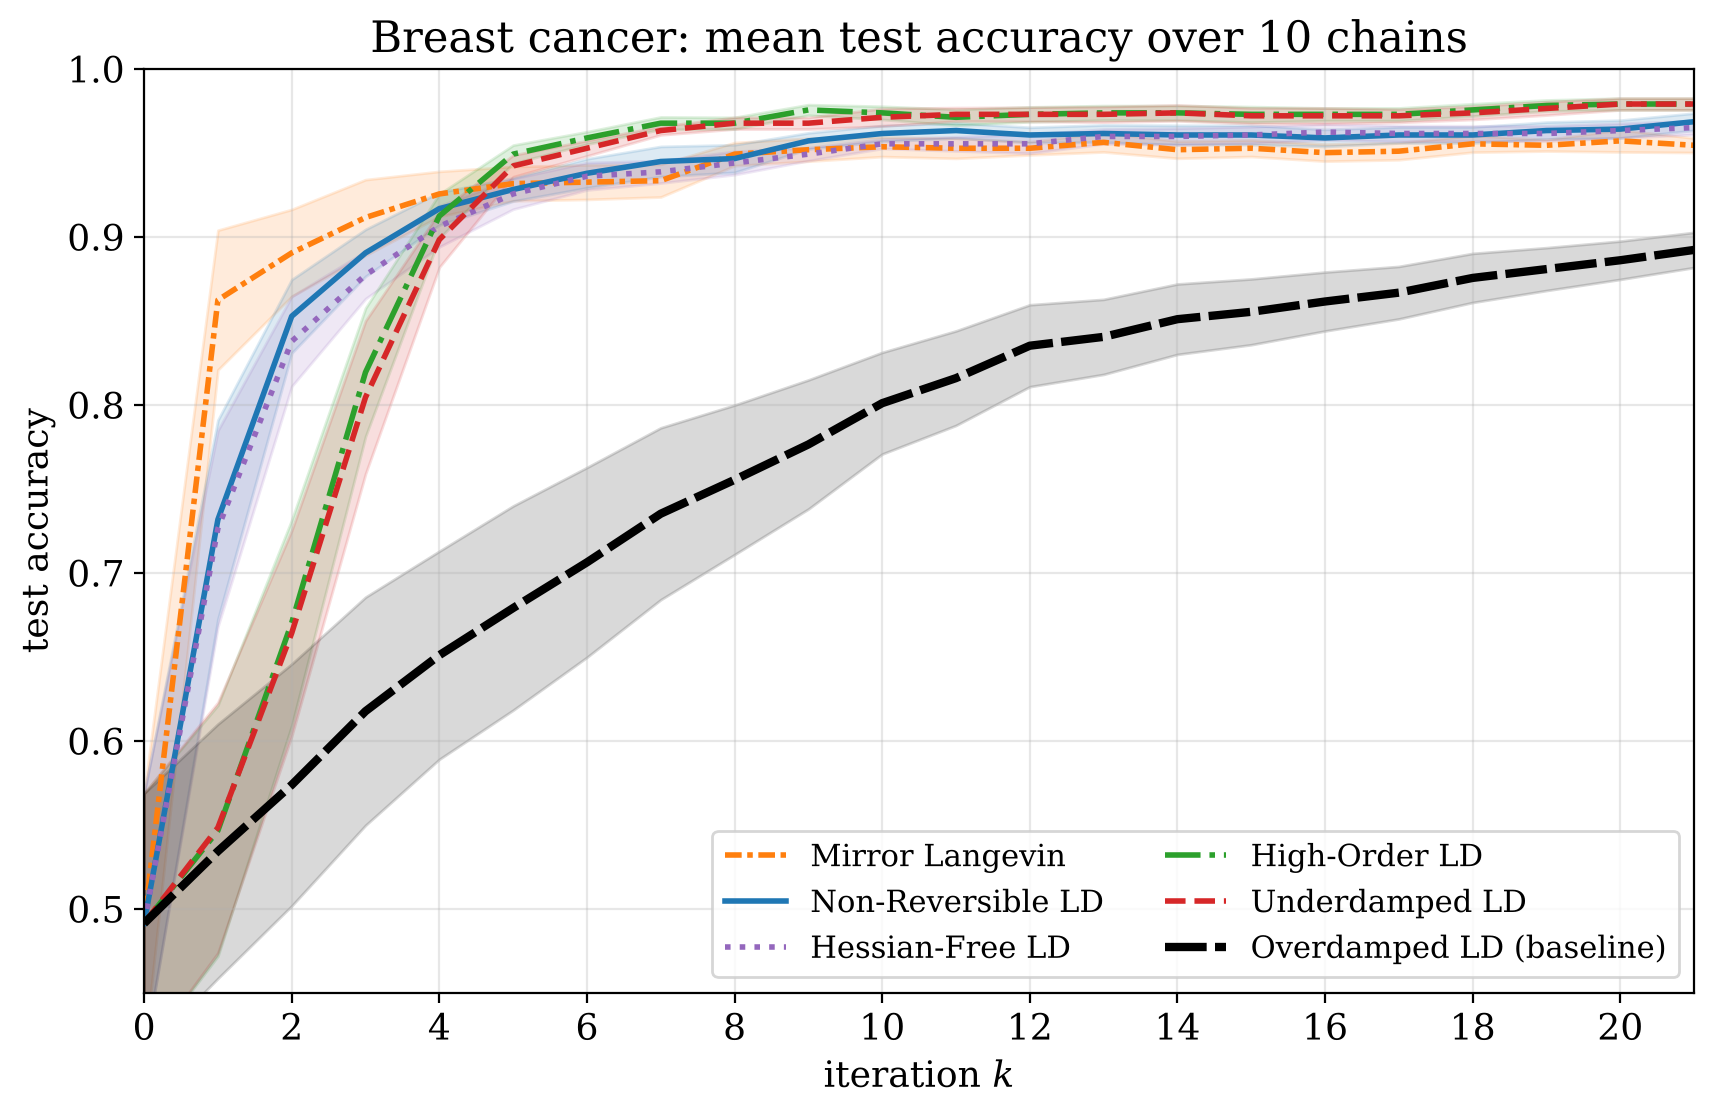

In [4]:
data = load_breast_cancer()
# column of ones, then scale. Scaling turns the ones into zeros, so there is no intercept
# in the end (kept like this so the numbers match the earlier runs)
X = scale(np.insert(data.data, 0, 1, axis=1))
X_train, X_test, y_train, y_test = train_test_split(X, data.target, test_size=0.2, random_state=42)

samplers = {
    "Overdamped LD":     (overdamped,     dict(h=3e-4)),
    "Underdamped LD":    (underdamped,    dict(h=0.02, gamma=4)),
    "High-Order LD":     (high_order,     dict(h=0.02, gamma=8, alpha=15)),
    "Non-Reversible LD": (non_reversible, dict(h=0.0015, c=0.5)),
    "Hessian-Free LD":   (hessian_free,   dict(h=0.003, gamma=0.5, alpha=15)),
    "Mirror Langevin":   (mirror,         dict(h=0.003)),
}

acc_bc = run_samplers(samplers, X_train, y_train, X_test, y_test)
plot_accuracy(acc_bc, "Breast cancer: mean test accuracy over 10 chains", "accuracy_breast_cancer")

## Synthetic data

Features $x_i \sim N(0, \Sigma)$, where $\Sigma$ has eigenvalues from 1 down to 1/300, and labels
$y_i \sim \mathrm{Bernoulli}\big(\sigma(x_i^\top \beta^\star + 0.3)\big)$. Since we know the true probabilities we also know
the Bayes-optimal accuracy (red dashed line).

Step sizes are in units of $1/\lambda_{\max}$, where $\lambda_{\max}$ is the largest eigenvalue of the Hessian of $U$ at the posterior mode.

In [5]:
rng = np.random.default_rng(0)
n, p = 5000, 20

# covariance with eigenvalues from 1 down to 1/300, in a random basis
eig = np.geomspace(1, 1 / 300, p)
Q, _ = np.linalg.qr(rng.normal(size=(p, p)))
L = np.linalg.cholesky(Q @ np.diag(eig) @ Q.T + 1e-12 * np.eye(p))
X = rng.normal(size=(n, p)) @ L.T

beta_true = rng.normal(size=p) * 0.5 / np.sqrt(eig)    # so every direction carries some signal
prob = sigmoid(X @ beta_true + 0.3)
y = (rng.random(n) < prob).astype(int)

train, test = train_test_split(np.arange(n), test_size=0.2, random_state=42, stratify=y)
X = (X - X[train].mean(0)) / X[train].std(0)    # standardise with the training mean and sd
X = np.insert(X, 0, 1, axis=1)                  # intercept
X_train, X_test, y_train, y_test = X[train], X[test], y[train], y[test]

bayes = np.mean(np.maximum(prob[test], 1 - prob[test]))    # best accuracy any classifier can get

In [6]:
# posterior mode by Newton's method, and the Hessian of U there
beta_map = np.zeros(p + 1)
for _ in range(20):
    s = sigmoid(X_train @ beta_map)
    H = X_train.T @ (X_train * (s * (1 - s))[:, None]) + (2 / LAM) * np.eye(p + 1)
    beta_map = beta_map - np.linalg.solve(H, grad_U(beta_map, X_train, y_train))

eigvals = np.linalg.eigvalsh(H)
h0 = 1 / eigvals[-1]                # step size unit
kappa = eigvals[-1] / eigvals[0]    # condition number of the posterior
print(f"kappa = {kappa:.1f}, Bayes-optimal accuracy = {bayes:.4f}")

kappa = 205.6, Bayes-optimal accuracy = 0.9332


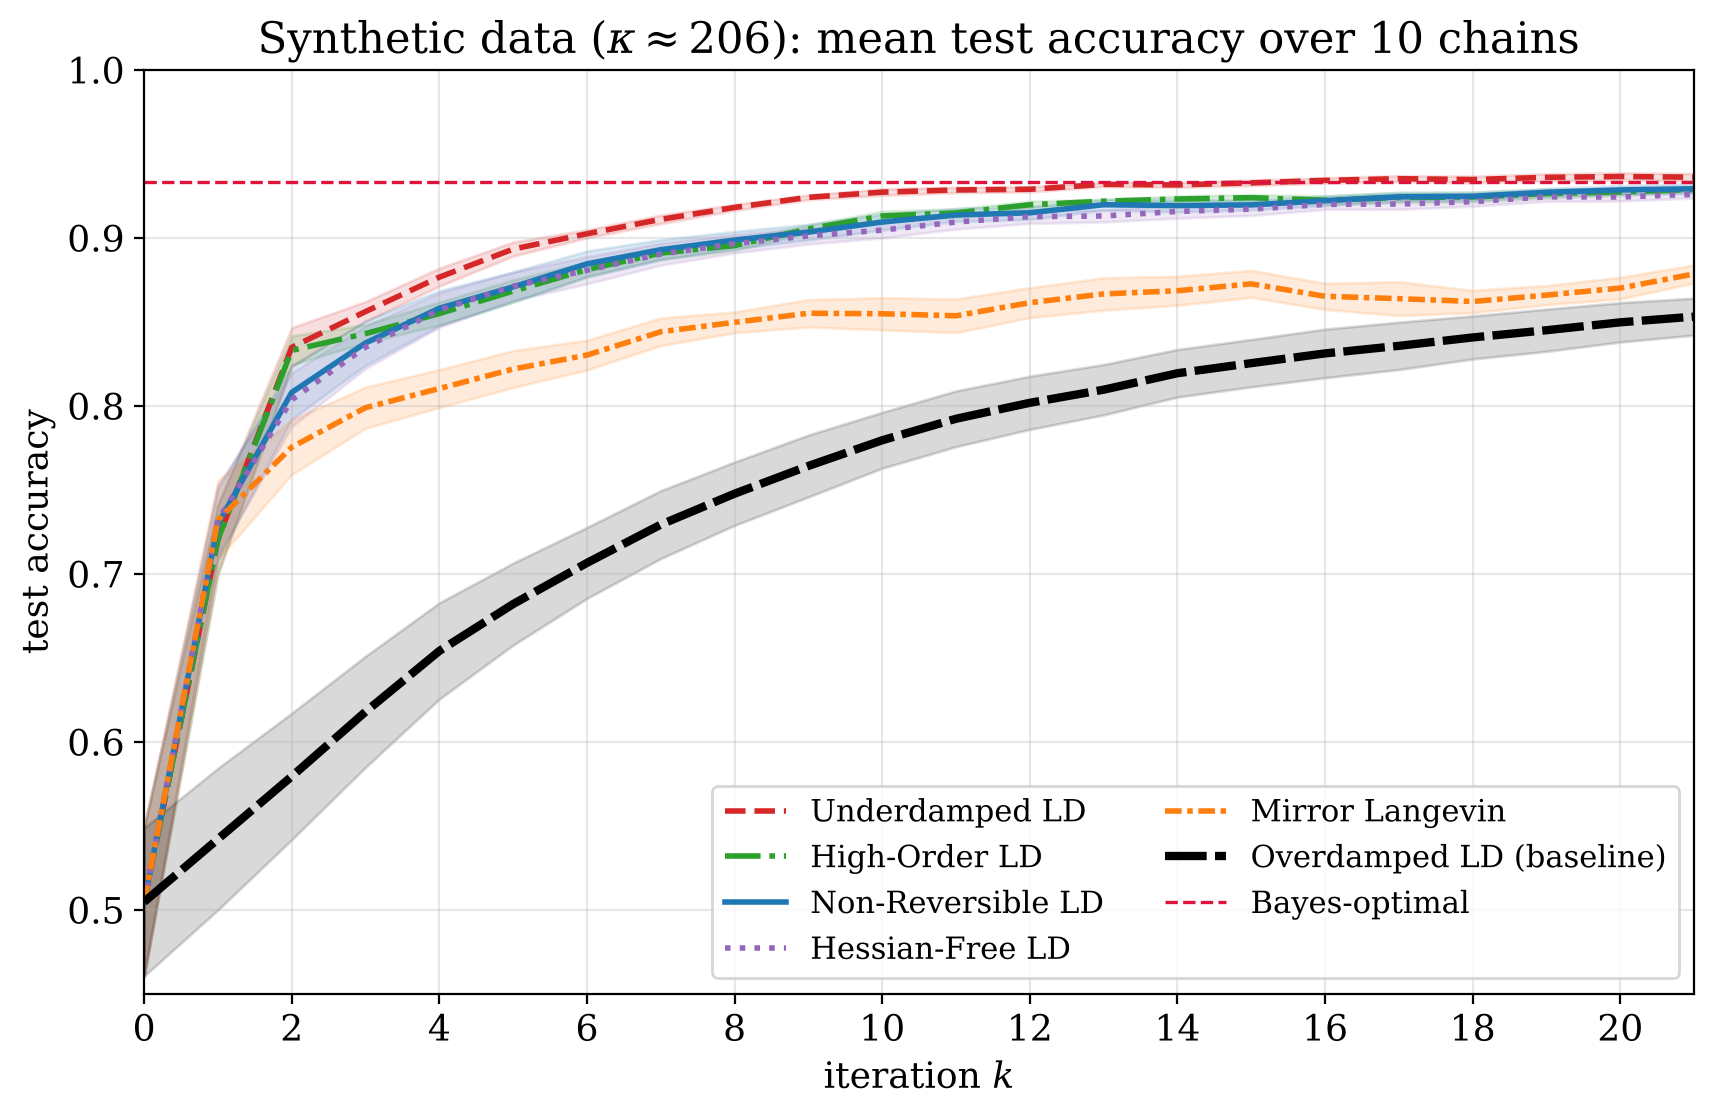

In [7]:
samplers = {
    "Overdamped LD":     (overdamped,     dict(h=0.1 * h0)),
    "Underdamped LD":    (underdamped,    dict(h=20 * h0, gamma=15)),
    "High-Order LD":     (high_order,     dict(h=20 * h0, gamma=15, alpha=60)),
    "Non-Reversible LD": (non_reversible, dict(h=0.5 * h0, c=0.1)),
    "Hessian-Free LD":   (hessian_free,   dict(h=1.0 * h0, gamma=0.5, alpha=60)),
    "Mirror Langevin":   (mirror,         dict(h=1.0 * h0)),
}

acc_syn = run_samplers(samplers, X_train, y_train, X_test, y_test)
plot_accuracy(acc_syn, rf"Synthetic data ($\kappa \approx {kappa:.0f}$): mean test accuracy over 10 chains",
              "accuracy_synthetic", bayes=bayes)

In both plots Overdamped runs with a deliberately small step size. With a tuned step size it matches or beats
the other samplers on test accuracy, so the gap here is as much about step sizes as about the dynamics.